# Rolling Beta with Confidence Band

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Estimates a stock's or fund's beta to the market over a moving window with a rolling regression, and draws a 95% confidence band around each estimate. Market exposure is not fixed, and a one-year estimate is noisy. The band shows which wiggles are real shifts in exposure and which are estimation error.

## When to use

- Monitor whether a fund's market exposure is drifting from its mandate
- Check if a stock became more or less defensive after a business change
- Show why a single "beta = 1.2" number can mislead

## Avoid when

- The window is too short for the return frequency (wide bands, little information)
- The relationship is clearly non-linear (options-like payoffs); beta summarises it poorly

## Alternatives

- Rolling correlation
- Scatter of stock vs. market returns for two sub-periods

## Design tips

- State the window and frequency (e.g. 252 daily returns)
- Draw beta = 1 (market-like) as a reference line
- Use the regression's standard error for the band, not ad-hoc smoothing

## Example

Simulated daily returns for a stock whose true beta moves from 0.8 to 1.4 and back to about 1.0, regressed on market returns over a rolling 252-day window with statsmodels RollingOLS. The real-data variant uses weekly 2018–2019 prices with a 52-week window. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from statsmodels.regression.rolling import RollingOLS
import statsmodels.api as sm

### Data

In [2]:
rng = np.random.default_rng(17)
dates = pd.bdate_range("2016-01-01", "2024-12-31")
n = len(dates)
true_beta = pd.Series(np.interp(np.arange(n), [0, 700, 1400, 1800, n - 1], [0.8, 0.8, 1.4, 1.0, 1.0]), index=dates)
market = rng.normal(0.0004, 0.010, n)
stock = 0.0001 + true_beta.values * market + rng.normal(0, 0.012, n)
rets = pd.DataFrame({"stock": stock, "market": market}, index=dates)
window = 252
label = "Stock"
title = "Rolling 1-year beta: market exposure is not constant (simulated)"
rets.head()

,stock,market
2016-01-01,0.011102,0.011413
2016-01-04,0.034273,0.003784
2016-01-05,-0.004437,-0.005000
2016-01-06,-0.013745,-0.012202
2016-01-07,-0.033003,-0.018546


### Plot

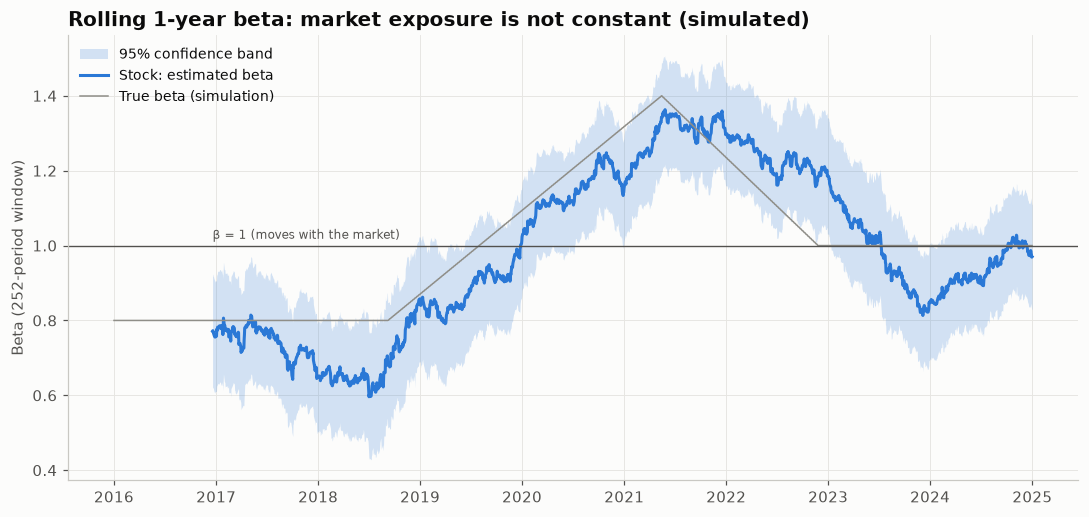

In [3]:
res = RollingOLS(rets["stock"], sm.add_constant(rets["market"]), window=window).fit()
beta = res.params["market"]
se = res.bse["market"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(beta.index, beta - 1.96 * se, beta + 1.96 * se, color=PALETTE[0], alpha=0.2,
                linewidth=0, label="95% confidence band")
ax.plot(beta.index, beta, color=PALETTE[0], label=f"{label}: estimated beta")
if true_beta is not None:
    ax.plot(true_beta.index, true_beta, color="#8f8e88", linewidth=1, label="True beta (simulation)")
ax.axhline(1, color="#52514e", linewidth=0.9)
ax.text(beta.dropna().index[0], 1.01, "β = 1 (moves with the market)", fontsize=8, color="#52514e", va="bottom")
ax.set_ylabel(f"Beta ({window}-period window)")
ax.set_title(title)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

## How to read it

The blue line is the estimated beta and the band its 95% confidence interval. In the simulation the thin gray line is the true beta: the estimate tracks it with a lag of about half a window. The band is wide enough that moves smaller than ±0.15 are not reliably real.

## Try it with real data

**Source:** plotly.express.data.stocks (weekly 2018–2019; AAPL vs. equal-weight of six tech stocks)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px

stocks = px.data.stocks().assign(date=lambda d: pd.to_datetime(d["date"])).set_index("date")
weekly = stocks.pct_change().dropna()
rets = pd.DataFrame({"stock": weekly["AAPL"], "market": weekly.mean(axis=1)})
window = 52
label = "AAPL"
true_beta = None
title = "AAPL rolling 52-week beta vs. equal-weight big tech"
rets.head()

,stock,market
date,,
2018-01-08,0.011943,0.020246
2018-01-15,0.007736,0.004146
2018-01-22,-0.038944,0.069417
2018-01-29,-0.064194,-0.024592
2018-02-05,-0.025483,-0.056030


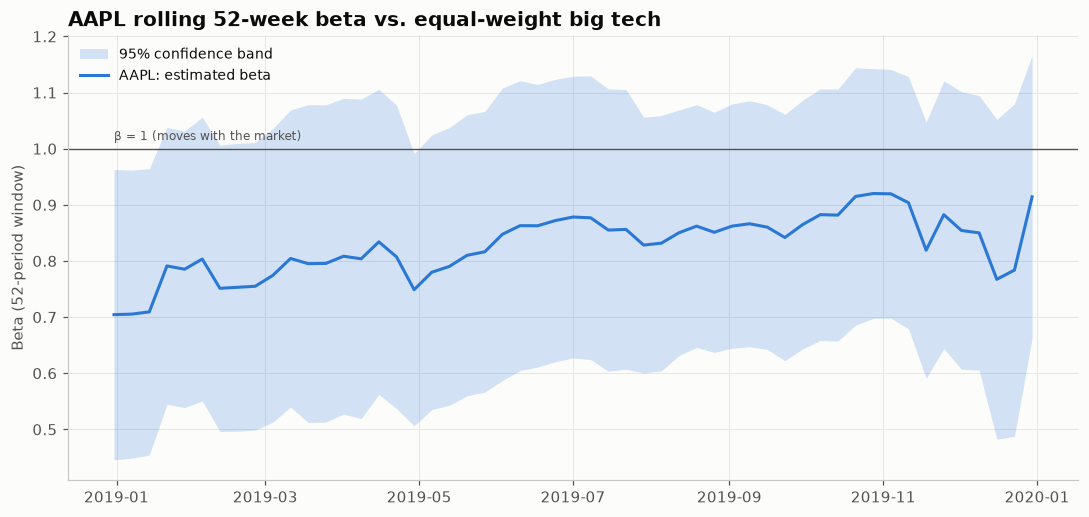

In [5]:
res = RollingOLS(rets["stock"], sm.add_constant(rets["market"]), window=window).fit()
beta = res.params["market"]
se = res.bse["market"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(beta.index, beta - 1.96 * se, beta + 1.96 * se, color=PALETTE[0], alpha=0.2,
                linewidth=0, label="95% confidence band")
ax.plot(beta.index, beta, color=PALETTE[0], label=f"{label}: estimated beta")
if true_beta is not None:
    ax.plot(true_beta.index, true_beta, color="#8f8e88", linewidth=1, label="True beta (simulation)")
ax.axhline(1, color="#52514e", linewidth=0.9)
ax.text(beta.dropna().index[0], 1.01, "β = 1 (moves with the market)", fontsize=8, color="#52514e", va="bottom")
ax.set_ylabel(f"Beta ({window}-period window)")
ax.set_title(title)
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

---
Standalone script: [`rolling_beta_ci.py`](rolling_beta_ci.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)